# 04 — Data Cleaning and Sensitivity Analysis

## 1. Imports and Configuration


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Ensure directories exist
os.makedirs('../../data/processed', exist_ok=True)
os.makedirs('../../outputs/figures', exist_ok=True)
os.makedirs('../../outputs/tables', exist_ok=True)

DATA_RAW_PATH = os.path.join('..', '..', 'data', 'raw', 'loan_dataset.xlsx')
if not os.path.exists(DATA_RAW_PATH):
    DATA_RAW_PATH = os.path.join('data', 'raw', 'loan_dataset.xlsx')

CLEANED_DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_cleaned.xlsx')
if not os.path.exists(os.path.dirname(CLEANED_DATA_PATH)):
    CLEANED_DATA_PATH = os.path.join('data', 'processed', 'loan_cleaned.xlsx')

print(f'Raw data source: {DATA_RAW_PATH}')
print(f'Cleaned data target: {CLEANED_DATA_PATH}')

Raw data source: ..\..\data\raw\loan_dataset.xlsx
Cleaned data target: ..\..\data\processed\loan_cleaned.xlsx


## 2. Ingesting Raw Data (Preserving Immutability)


In [2]:
df_raw = pd.read_excel(DATA_RAW_PATH, sheet_name='Loan_Data')
print(f'Ingested raw dataset: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns.')

Ingested raw dataset: 10,100 rows x 41 columns.


## 3. Deduplication


In [3]:
dup_count = df_raw.duplicated().sum()
df_dedup = df_raw.drop_duplicates().reset_index(drop=True)

print(f'Duplicate rows removed: {dup_count}')
print(f'Remaining unique records: {df_dedup.shape[0]:,} rows x {df_dedup.shape[1]} columns.')

Duplicate rows removed: 100
Remaining unique records: 10,000 rows x 41 columns.


## 4. Reusable Data Cleaning Pipeline Function


In [4]:
def clean_loan_data(df_input: pd.DataFrame) -> pd.DataFrame:
    """
    Reusable, production-grade data cleaning function for the Loan Default dataset.
    
    Operations performed:
    1. Removes duplicate records based on Applicant_ID.
    2. Converts hidden string 'N/A' in Savings_Balance to genuine NaN and numeric type.
    3. Standardizes categorical labels:
       - Gender: 'Male' / 'Female'
       - Employment_Type: 'Salaried', 'Self-Employed', 'Contract', 'Unemployed', 'Retired'
       - Employer_Sector: Standardized 9 categories
    4. Replaces impossible / sentinel values with NaN:
       - Age: < 18 or > 90 -> NaN
       - Credit_Score: == 9999 -> NaN (valid range: 300 to 850)
       - Years_Employed: < 0 -> NaN
    5. Corrects unit inconsistency in Interest_Rate_Pct (values < 1.0 multiplied by 100).
    6. Retains negative Checking_Balance as valid economic overdraft indicator.
    7. Creates structural indicator flags (Ever_Delinquent, Is_Home_Loan).
    """
    df = df_input.copy()
    
    # 1. Deduplication
    df = df.drop_duplicates(subset=['Applicant_ID']).reset_index(drop=True)
    
    # 2. Hidden text in Savings_Balance
    if df['Savings_Balance'].dtype == 'object':
        df['Savings_Balance'] = df['Savings_Balance'].replace('N/A', np.nan)
    df['Savings_Balance'] = pd.to_numeric(df['Savings_Balance'], errors='coerce')
    
    # 3. Categorical Label Standardisation
    # Gender
    gender_map = {
        'male': 'Male', 'm': 'Male', 'M': 'Male', 'MALE': 'Male',
        'female': 'Female', 'f': 'Female', 'F': 'Female', 'Female ': 'Female',
        'Female': 'Female', 'Male': 'Male'
    }
    df['Gender'] = df['Gender'].astype(str).str.strip().map(gender_map).fillna(df['Gender'])
    
    # Employment_Type
    emp_map = {
        'Self employed': 'Self-Employed',
        'self-employed': 'Self-Employed',
        'salaried': 'Salaried',
        'Salaried': 'Salaried',
        'Self-Employed': 'Self-Employed',
        'Contract': 'Contract',
        'Unemployed': 'Unemployed',
        'Retired': 'Retired'
    }
    df['Employment_Type'] = df['Employment_Type'].astype(str).str.strip().map(emp_map).fillna(df['Employment_Type'])
    
    # Employer_Sector
    sec_map = {
        'IT / Finance': 'IT/Finance',
        'public sector': 'Public Sector',
        'Public Sector': 'Public Sector',
        'IT/Finance': 'IT/Finance'
    }
    df['Employer_Sector'] = df['Employer_Sector'].astype(str).str.strip().replace(sec_map)
    
    # 4. Impossible values and sentinels -> set to NaN for pipeline imputation
    df.loc[(df['Age'] < 18) | (df['Age'] > 90), 'Age'] = np.nan
    df.loc[df['Credit_Score'] == 9999, 'Credit_Score'] = np.nan
    df.loc[df['Years_Employed'] < 0, 'Years_Employed'] = np.nan
    
    # 5. Unit inconsistency: Interest_Rate_Pct < 1.0 (decimals to percentages)
    mask_rate = df['Interest_Rate_Pct'] < 1.0
    df.loc[mask_rate, 'Interest_Rate_Pct'] = df.loc[mask_rate, 'Interest_Rate_Pct'] * 100.0
    
    # 6. Structural domain flags
    df['Ever_Delinquent'] = (df['Late_Payments_2Y'] > 0).astype(int)
    df['Is_Home_Loan'] = (df['Loan_Purpose'] == 'Home').astype(int)
    
    return df

# Execute cleaning pipeline
df_cleaned = clean_loan_data(df_raw)
print(f'Dataset successfully cleaned via clean_loan_data()!')
print(f'Cleaned shape: {df_cleaned.shape[0]:,} rows x {df_cleaned.shape[1]} columns.')

Dataset successfully cleaned via clean_loan_data()!
Cleaned shape: 10,000 rows x 43 columns.


### Verification of Remaining Missing Values


In [5]:
remaining_nulls = df_cleaned.isnull().sum()
remaining_null_table = pd.DataFrame({
    'Column': remaining_nulls.index,
    'Remaining_NaN_Count': remaining_nulls.values,
    'Remaining_NaN_Pct': (remaining_nulls.values / len(df_cleaned)) * 100
}).query('Remaining_NaN_Count > 0').sort_values('Remaining_NaN_Count', ascending=False).reset_index(drop=True)

remaining_null_table['Nature'] = remaining_null_table['Column'].apply(
    lambda c: 'Structural (Conditioned on zero delinquency / non-home loan)' 
    if c in ['Property_Value', 'Months_Since_Last_Delinquency'] 
    else 'True Missing (To be imputed within CV Pipeline)'
)

print('=== REMAINING MISSING VALUES AFTER CLEANING ===')
display(remaining_null_table)

=== REMAINING MISSING VALUES AFTER CLEANING ===


,Column,Remaining_NaN_Count,Remaining_NaN_Pct,Nature
0,Property_Value,8227,82.27,Structural (Conditioned on zero delinquency / ...
1,Months_Since_Last_Delinquency,7170,71.70,Structural (Conditioned on zero delinquency / ...
2,Savings_Balance,605,6.05,True Missing (To be imputed within CV Pipeline)
3,Years_Employed,529,5.29,True Missing (To be imputed within CV Pipeline)
4,Annual_Income,463,4.63,True Missing (To be imputed within CV Pipeline)
5,Education_Level,381,3.81,True Missing (To be imputed within CV Pipeline)
6,Residence_Years,378,3.78,True Missing (To be imputed within CV Pipeline)
7,Credit_History_Years,312,3.12,True Missing (To be imputed within CV Pipeline)
8,Total_Credit_Limit,307,3.07,True Missing (To be imputed within CV Pipeline)
9,Credit_Score,289,2.89,True Missing (To be imputed within CV Pipeline)


## 5. Credit Score Sentinel Impact Analysis


In [6]:
# 1. Calculation with sentinel 9999 included (raw data)
raw_mean_def = df_dedup[df_dedup['Loan_Default'] == 'Yes']['Credit_Score'].mean()
raw_mean_non = df_dedup[df_dedup['Loan_Default'] == 'No']['Credit_Score'].mean()
raw_gap = raw_mean_non - raw_mean_def

# 2. Calculation after sentinel 9999 converted to NaN
clean_mean_def = df_cleaned[df_cleaned['Loan_Default'] == 'Yes']['Credit_Score'].mean()
clean_mean_non = df_cleaned[df_cleaned['Loan_Default'] == 'No']['Credit_Score'].mean()
clean_gap = clean_mean_non - clean_mean_def

# Display comparative table
cs_comparison = pd.DataFrame({
    'Condition': ['With 9999 Sentinel (Corrupted)', 'With 9999 -> NaN (Cleaned)', 'Discrepancy (Bias)'],
    'Defaulter_Mean_Credit_Score': [raw_mean_def, clean_mean_def, raw_mean_def - clean_mean_def],
    'Non_Defaulter_Mean_Credit_Score': [raw_mean_non, clean_mean_non, raw_mean_non - clean_mean_non],
    'Score_Divergence_Gap': [raw_gap, clean_gap, raw_gap - clean_gap]
})
display(cs_comparison)

,Condition,Defaulter_Mean_Credit_Score,Non_Defaulter_Mean_Credit_Score,Score_Divergence_Gap
0,With 9999 Sentinel (Corrupted),628.570016,705.207029,76.637014
1,With 9999 -> NaN (Cleaned),618.804065,700.436088,81.632024
2,Discrepancy (Bias),9.765951,4.770941,-4.995010


## 6. Outlier Analysis & Skewness Mitigation


In [7]:
# IQR Rule on Annual_Income
q1 = df_cleaned['Annual_Income'].quantile(0.25)
q3 = df_cleaned['Annual_Income'].quantile(0.75)
iqr = q3 - q1
iqr_upper_bound = q3 + 1.5 * iqr
iqr_lower_bound = max(0, q1 - 1.5 * iqr)

outliers_iqr = df_cleaned[df_cleaned['Annual_Income'] > iqr_upper_bound]
num_outliers = len(outliers_iqr)

print('=== Annual_Income IQR Outlier Analysis ===')
print(f'25th Percentile:   ${q1:,.2f}')
print(f'75th Percentile:   ${q3:,.2f}')
print(f'Interquartile Range:    ${iqr:,.2f}')
print(f'IQR Upper Bound Threshold: ${iqr_upper_bound:,.2f}')
print(f'Flagged Outliers (Income > ${iqr_upper_bound:,.0f}): {num_outliers} ({num_outliers/len(df_cleaned)*100:.2f}%)')
print(f'Default Rate among Outliers: {(outliers_iqr["Loan_Default"] == "Yes").mean()*100:.2f}%')


=== Annual_Income IQR Outlier Analysis ===
25th Percentile:   $25,700.00
75th Percentile:   $54,300.00
Interquartile Range:    $28,600.00
IQR Upper Bound Threshold: $97,200.00
Flagged Outliers (Income > $97,200): 352 (3.52%)
Default Rate among Outliers: 11.93%


In [8]:
# Skewness Analysis & Log Transformation
skew_results = []
money_features = ['Annual_Income', 'Loan_Amount', 'Savings_Balance']

for feat in money_features:
    raw_s = df_cleaned[feat].skew()
    log_s = np.log1p(df_cleaned[feat].dropna()).skew()
    skew_results.append({
        'Feature': feat,
        'Raw_Skewness': raw_s,
        'Post_Log1p_Skewness': log_s,
        'Skewness_Reduction': abs(raw_s) - abs(log_s),
        'Normality_Assessment': 'Strongly Right-Skewed' if raw_s > 1.5 else 'Moderately Skewed'
    })

df_skew_table = pd.DataFrame(skew_results)
df_skew_table.to_csv('../../outputs/tables/skewness_analysis.csv', index=False)
display(df_skew_table)


,Feature,Raw_Skewness,Post_Log1p_Skewness,Skewness_Reduction,Normality_Assessment
0,Annual_Income,4.589207,-0.389665,4.199542,Strongly Right-Skewed
1,Loan_Amount,2.591248,0.095939,2.495310,Strongly Right-Skewed
2,Savings_Balance,6.567277,-2.052191,4.515086,Strongly Right-Skewed


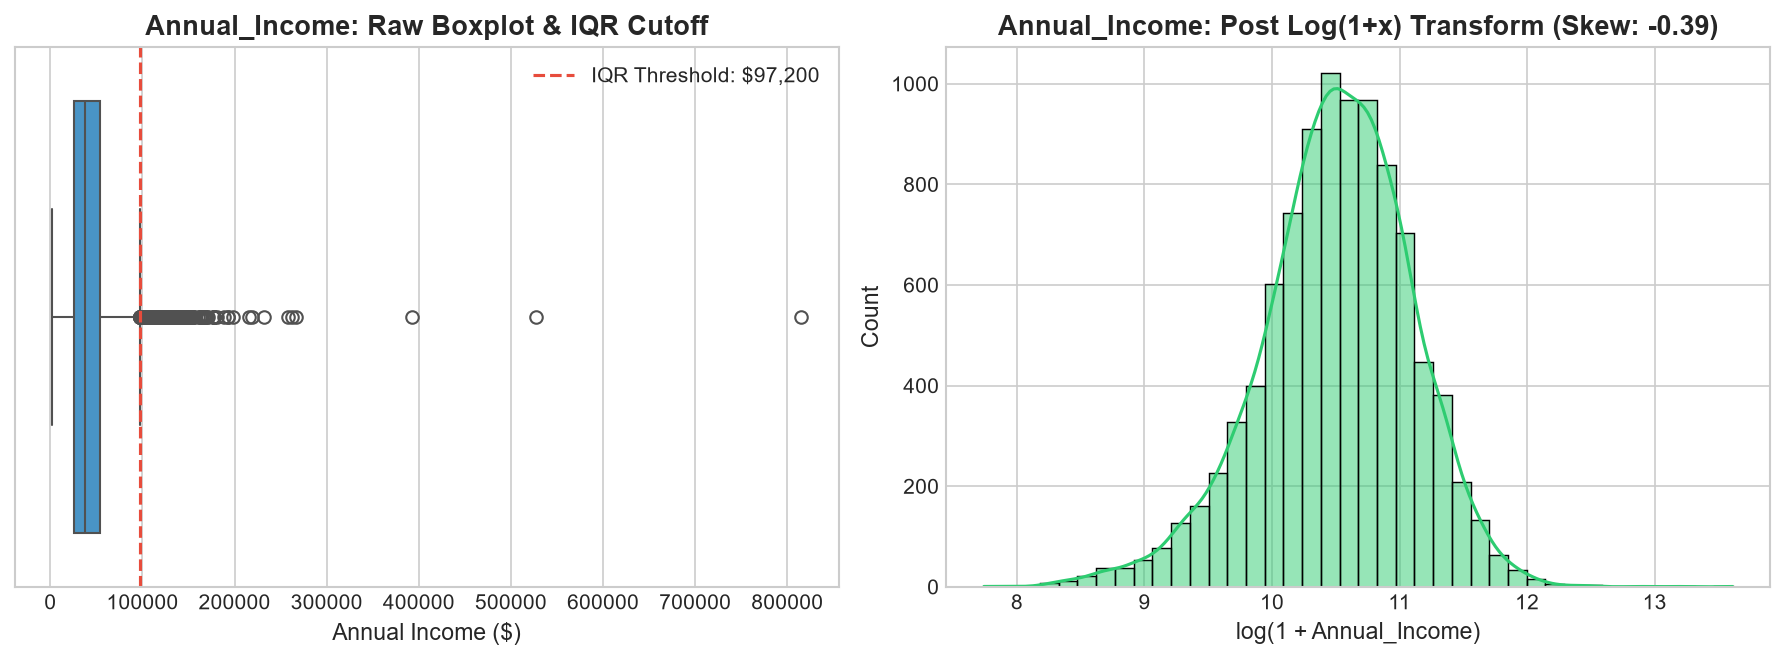

In [9]:
# Visualise Outliers and Log Transform Effect
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Boxplot of raw income with IQR cutoff
sns.boxplot(x=df_cleaned['Annual_Income'], ax=axes[0], color='#3498db')
axes[0].axvline(iqr_upper_bound, color='#e74c3c', linestyle='--', label=f'IQR Threshold: ${iqr_upper_bound:,.0f}')
axes[0].set_title('Annual_Income: Raw Boxplot & IQR Cutoff', weight='bold')
axes[0].set_xlabel('Annual Income ($)')
axes[0].legend()

# Histplot of log-transformed income
sns.histplot(np.log1p(df_cleaned['Annual_Income'].dropna()), kde=True, ax=axes[1], color='#2ecc71', bins=40)
axes[1].set_title(f'Annual_Income: Post Log(1+x) Transform (Skew: {np.log1p(df_cleaned["Annual_Income"].dropna()).skew():.2f})', weight='bold')
axes[1].set_xlabel('log(1 + Annual_Income)')

plt.tight_layout()
plt.savefig('../../outputs/figures/income_iqr_outliers.png', dpi=150)
plt.show()

**Takeaway:** The log transformation `log(1 + Income)` successfully compresses extreme positive skewness, transforming an asymmetrical long-tailed distribution into a well-behaved bell curve suitable for linear and distance-based estimators.

## 7. Cleaning Sensitivity Analysis


In [10]:
# Construct 4 cleaning experiment variations on Annual_Income
s_base = df_cleaned['Annual_Income'].copy()

# Experiment 1: Baseline Clean (Median Imputation)
imp_median = s_base.fillna(s_base.median())

# Experiment 2: Mean Imputation
imp_mean = s_base.fillna(s_base.mean())

# Experiment 3: Outlier Capping (Winsorization at 99th percentile + Median Imputation)
p99 = s_base.quantile(0.99)
capped_income = s_base.clip(upper=p99)
imp_capped = capped_income.fillna(capped_income.median())

# Experiment 4: Listwise Deletion of IQR Outliers (> $97,200)
del_income = s_base[s_base <= iqr_upper_bound].dropna()

# Compile Sensitivity Table
sensitivity_metrics = []
for name, series in [
    ('Baseline (Median Imputation)', imp_median),
    ('Alternative A (Mean Imputation)', imp_mean),
    ('Alternative B (99th Capping + Median)', imp_capped),
    ('Alternative C (Outlier Deletion)', del_income)
]:
    sensitivity_metrics.append({
        'Cleaning_Strategy': name,
        'Sample_Size': len(series),
        'Mean_Income': series.mean(),
        'Std_Income': series.std(),
        'Median_Income': series.median(),
        'Skewness': series.skew(),
        'Correlation_with_Loan_Amount': df_cleaned.loc[series.index, 'Loan_Amount'].corr(series)
    })

df_sensitivity = pd.DataFrame(sensitivity_metrics)
df_sensitivity.to_csv('../../outputs/tables/cleaning_sensitivity_comparison.csv', index=False)
display(df_sensitivity)

,Cleaning_Strategy,Sample_Size,Mean_Income,Std_Income,Median_Income,Skewness,Correlation_with_Loan_Amount
0,Baseline (Median Imputation),10000,42708.090000,26476.822955,37400.0,4.714277,0.258831
1,Alternative A (Mean Imputation),10000,42965.785887,26450.976239,38700.0,4.699250,0.259466
2,Alternative B (99th Capping + Median),10000,42329.098800,23483.603199,37400.0,1.254212,0.286650
3,Alternative C (Outlier Deletion),9185,39799.673381,19658.719060,36500.0,0.652869,0.268099


## 8. Preserving and Exporting the Cleaned Dataset


In [11]:
# Export cleaned dataset to Excel
with pd.ExcelWriter(CLEANED_DATA_PATH, engine='openpyxl') as writer:
    df_cleaned.to_excel(writer, sheet_name='Loan_Cleaned', index=False)

print(f'Successfully exported clean dataset to: {CLEANED_DATA_PATH}')

Successfully exported clean dataset to: ..\..\data\processed\loan_cleaned.xlsx
